--- YÊU CẦU 1 & 2: TÌM K TỐI ƯU (SAU KHI CHUẨN HÓA) ---
K =  1 -> Độ chính xác (Accuracy): 1.0000
K =  2 -> Độ chính xác (Accuracy): 1.0000
K =  3 -> Độ chính xác (Accuracy): 1.0000
K =  4 -> Độ chính xác (Accuracy): 1.0000
K =  5 -> Độ chính xác (Accuracy): 1.0000
K =  6 -> Độ chính xác (Accuracy): 1.0000
K =  7 -> Độ chính xác (Accuracy): 1.0000
K =  8 -> Độ chính xác (Accuracy): 1.0000
K =  9 -> Độ chính xác (Accuracy): 1.0000
K = 10 -> Độ chính xác (Accuracy): 1.0000
K = 11 -> Độ chính xác (Accuracy): 1.0000
K = 12 -> Độ chính xác (Accuracy): 1.0000
K = 13 -> Độ chính xác (Accuracy): 1.0000
K = 14 -> Độ chính xác (Accuracy): 1.0000
K = 15 -> Độ chính xác (Accuracy): 1.0000


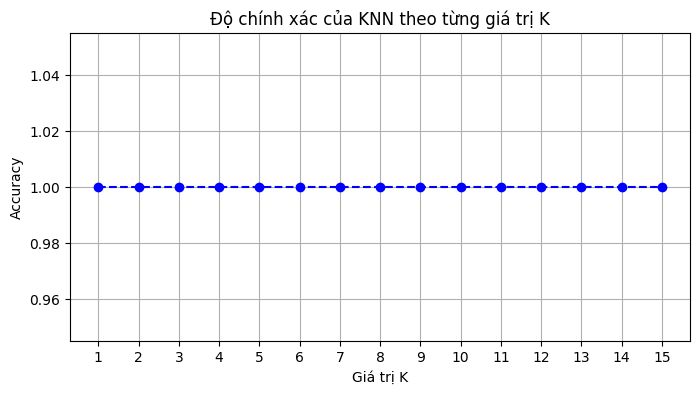


--- YÊU CẦU 3: SO SÁNH CÁC LOẠI KHOẢNG CÁCH (K=5) ---
Khoảng cách Euclidean (Mặc định, p=2): Accuracy = 1.0000
Khoảng cách Manhattan (p=1): Accuracy = 1.0000
Khoảng cách Minkowski (p=3): Accuracy = 1.0000


In [5]:
#Bai 1
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Tải dữ liệu Iris
iris = load_iris()
X = iris.data
y = iris.target

# Chia tập dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Yêu cầu 2: Chuẩn hóa dữ liệu đầu vào
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Yêu cầu 1: Thực nghiệm với các giá trị K khác nhau (từ 1 đến 15)
k_values = range(1, 16)
accuracies = []

print("--- YÊU CẦU 1 & 2: TÌM K TỐI ƯU (SAU KHI CHUẨN HÓA) ---")
for k in k_values:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(X_train_scaled, y_train)
    y_pred = knn_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"K = {k:2d} -> Độ chính xác (Accuracy): {acc:.4f}")

# Vẽ biểu đồ chọn K tối ưu
plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o', linestyle='--', color='b')
plt.title("Độ chính xác của KNN theo từng giá trị K")
plt.xlabel("Giá trị K")
plt.ylabel("Accuracy")
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Yêu cầu 3: Thực nghiệm với các đơn vị tính khoảng cách khác nhau (chọn K=5)
print("\n--- YÊU CẦU 3: SO SÁNH CÁC LOẠI KHOẢNG CÁCH (K=5) ---")
metrics = [
    ("Euclidean (Mặc định, p=2)", "euclidean", 2),
    ("Manhattan (p=1)", "manhattan", 1),
    ("Minkowski (p=3)", "minkowski", 3)
]

for name, metric_name, p_val in metrics:
    knn_model = KNeighborsClassifier(n_neighbors=5, metric=metric_name, p=p_val)
    knn_model.fit(X_train_scaled, y_train)
    y_pred = knn_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    print(f"Khoảng cách {name}: Accuracy = {acc:.4f}")

In [6]:
#Bai 2
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải tập dữ liệu Boston Housing
boston = fetch_openml(name="boston", version=1, as_frame=True, parser="auto")
df = boston.frame.astype(float)

X = df.drop(columns=['MEDV'])
y = df['MEDV']

# 2. Phân chia dữ liệu (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu (Rất quan trọng với KNN vì KNN tính khoảng cách)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4 & 5. Áp dụng KNN Regressor với k = 3, 5, 7, 9 và đánh giá
print("--- KẾT QUẢ BÀI 2: KNN REGRESSOR TRÊN BOSTON HOUSING ---")
k_list = [3, 5, 7, 9]

for k in k_list:
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(X_train_scaled, y_train)
    y_pred = knn_reg.predict(X_test_scaled)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"K = {k} | MSE: {mse:.4f} | R^2 score: {r2:.4f}")

--- KẾT QUẢ BÀI 2: KNN REGRESSOR TRÊN BOSTON HOUSING ---
K = 3 | MSE: 19.4043 | R^2 score: 0.7354
K = 5 | MSE: 20.6055 | R^2 score: 0.7190
K = 7 | MSE: 23.4155 | R^2 score: 0.6807
K = 9 | MSE: 24.0094 | R^2 score: 0.6726


CÁCH CHIA DỮ LIỆU: 80% Huấn luyện - 20% Kiểm tra
Độ chính xác (Accuracy): 1.0000
Báo cáo phân loại:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

CÁCH CHIA DỮ LIỆU: 70% Huấn luyện - 30% Kiểm tra
Độ chính xác (Accuracy): 1.0000
Báo cáo phân loại:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

CÁCH CHIA DỮ LIỆU: 60% Huấn luyện - 40

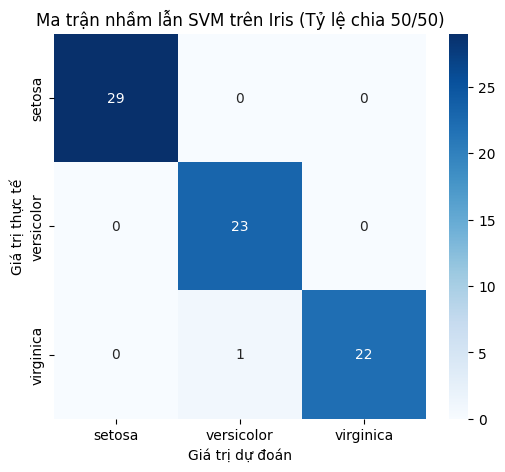

In [7]:
#Bai 3
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Tải dữ liệu Iris
iris = load_iris()
X = iris.data
y = iris.target

# Thử nghiệm các cách chia dữ liệu khác nhau (tỷ lệ tập kiểm tra: 20%, 30%, 40%, 50%)
test_sizes = [0.2, 0.3, 0.4, 0.5]

for ts in test_sizes:
    train_pct = int((1 - ts) * 100)
    test_pct = int(ts * 100)
    print(f"==================================================")
    print(f"CÁCH CHIA DỮ LIỆU: {train_pct}% Huấn luyện - {test_pct}% Kiểm tra")

    # Chia dữ liệu
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ts, random_state=42)

    # Chuẩn hóa dữ liệu
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Xây dựng và huấn luyện mô hình SVM
    svm_model = SVC(kernel='rbf', C=1, gamma='scale')
    svm_model.fit(X_train_scaled, y_train)

    # Dự đoán và đánh giá
    y_pred = svm_model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    conf_matrix = confusion_matrix(y_test, y_pred)

    print(f"Độ chính xác (Accuracy): {accuracy:.4f}")
    print("Báo cáo phân loại:")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))

# Trực quan hóa ma trận nhầm lẫn của lần chia cuối cùng (hoặc chọn tỷ lệ 80/20)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Giá trị dự đoán")
plt.ylabel("Giá trị thực tế")
plt.title(f"Ma trận nhầm lẫn SVM trên Iris (Tỷ lệ chia {train_pct}/{test_pct})")
plt.show()

In [8]:
#Bai 4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải tập dữ liệu Boston Housing
boston = fetch_openml(name="boston", version=1, as_frame=True, parser="auto")
df = boston.frame.astype(float)

X = df.drop(columns=['MEDV'])
y = df['MEDV']

# 2. Phân chia dữ liệu (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu (Bắt buộc đối với SVM/SVR)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Thực nghiệm SVR với kernel='linear' và kernel='rbf'
print("--- KẾT QUẢ BÀI 4: SVR TRÊN DỮ LIỆU BOSTON HOUSING ---")
kernels = ['linear', 'rbf']

for k_type in kernels:
    # Xây dựng mô hình SVR (với rbf tăng nhẹ C=10 để mô hình học tốt biên độ giá nhà)
    if k_type == 'linear':
        svr_model = SVR(kernel='linear', C=1.0)
    else:
        svr_model = SVR(kernel='rbf', C=10.0, gamma='scale')

    svr_model.fit(X_train_scaled, y_train)
    y_pred = svr_model.predict(X_test_scaled)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"Kernel = '{k_type:6s}' | MSE: {mse:.4f} | R^2 score: {r2:.4f}")

--- KẾT QUẢ BÀI 4: SVR TRÊN DỮ LIỆU BOSTON HOUSING ---
Kernel = 'linear' | MSE: 28.9185 | R^2 score: 0.6057
Kernel = 'rbf   ' | MSE: 12.7382 | R^2 score: 0.8263
